In [1]:
import earthaccess
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

#import sys
#sys.path.append("projects/earthaccess_sandbox/")
import read_sat_functions as rs

In [2]:
auth = earthaccess.login()

In [3]:
lfile = earthaccess.search_data(
    short_name="PACE_OCI_L2_CLOSE",
    granule_name="*20250315T152616*",
)
cfile = earthaccess.search_data(
    short_name="PACE_OCI_MI_CLOSE",
    granule_name="*20250315T152616*",
)

In [4]:
ldata = rs.open_data(lfile)
ldata = ldata.set_coords(("longitude", "latitude"))
cdata = rs.open_data(cfile)
cdata = cdata.set_coords(("longitude", "latitude"))

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Text(0.5, 1.0, 'L2 Chl')

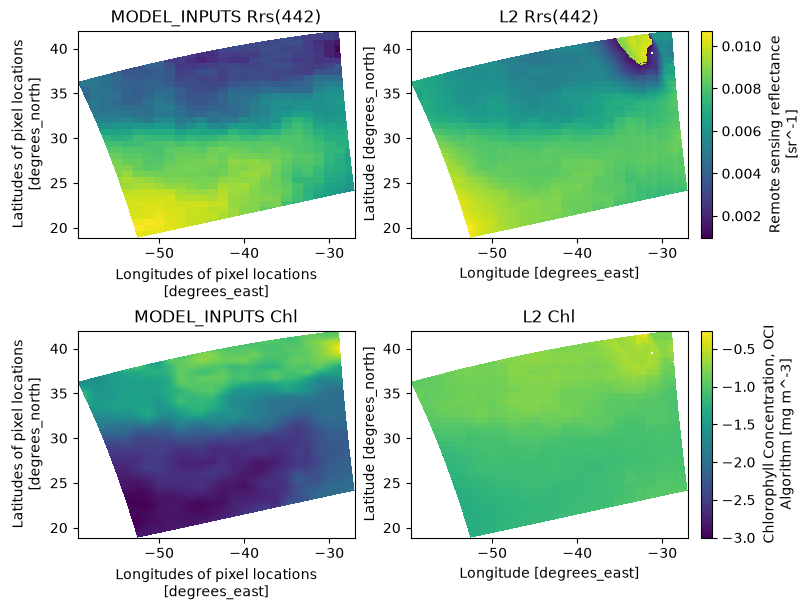

In [11]:
fig = plt.figure(figsize=(8, 6), constrained_layout=True)
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

m1 = (
    cdata["Rrs"]
    .sel({"wavelength": 442}, method="nearest")
    .plot(ax=ax1, x="longitude", y="latitude", add_colorbar=False)
)
ax1.set_title("MODEL_INPUTS Rrs(442)")

m2 = (
    ldata["Rrs"]
    .sel({"wavelength_3d": 442}, method="nearest")
    .plot(ax=ax2, x="longitude", y="latitude", add_colorbar=True)
)
ax2.set_title("L2 Rrs(442)")

m3 = (
    np.log10(cdata["chlor_a"])
    .plot(ax=ax3, x="longitude", y="latitude", add_colorbar=False)
)
ax3.set_title("MODEL_INPUTS Chl")

m4 = (
    np.log10(ldata["chlor_a"])
    .plot(ax=ax4, x="longitude", y="latitude", add_colorbar=True)
)
ax4.set_title("L2 Chl")

In [12]:
llon = ldata.longitude.values
llat = ldata.latitude.values
clon = cdata.longitude.values
clat = cdata.latitude.values

#tlat = 32.0
#tlon = -39.0
tlat = 25.0
tlon = -50.0

lrow, lcol = rs.find_closest_pixel(llat, llon, tlat, tlon)
crow, ccol = rs.find_closest_pixel(clat, clon, tlat, tlon)

print(f"Closest l2 pixel is at row {lrow}, col {lcol}")
print(f"Pixel Coordinates: Lat {llat[lrow, lcol]:.2f}, Lon {llon[lrow, lcol]:.2f}")
print(f"Closest input pixel is at row {crow}, col {ccol}")
print(f"Pixel Coordinates: Lat {clat[crow, ccol]:.2f}, Lon {clon[crow, ccol]:.2f}")

Closest l2 pixel is at row 503, col 91
Pixel Coordinates: Lat 24.99, Lon -50.01
Closest input pixel is at row 503, col 91
Pixel Coordinates: Lat 24.99, Lon -50.01


In [13]:
lwl = ldata.wavelength_3d.values
print(lwl)
print(len(lwl))

cwl = cdata.wavelength.values
print(cwl)
print(len(cwl))

[346. 348. 351. 353. 356. 358. 361. 363. 366. 368. 371. 373. 375. 378.
 380. 383. 385. 388. 390. 393. 395. 398. 400. 403. 405. 408. 410. 413.
 415. 418. 420. 422. 425. 427. 430. 432. 435. 437. 440. 442. 445. 447.
 450. 452. 455. 457. 460. 462. 465. 467. 470. 472. 475. 477. 480. 482.
 485. 487. 490. 492. 495. 497. 500. 502. 505. 507. 510. 512. 515. 517.
 520. 522. 525. 527. 530. 532. 535. 537. 540. 542. 545. 547. 550. 553.
 555. 558. 560. 563. 565. 568. 570. 573. 575. 578. 580. 583. 586. 588.
 591. 593. 596. 598. 601. 603. 605. 608. 610. 613. 615. 618. 620. 623.
 625. 627. 630. 632. 635. 637. 640. 641. 642. 643. 645. 646. 647. 648.
 650. 651. 652. 653. 655. 656. 657. 658. 660. 661. 662. 663. 665. 666.
 667. 668. 670. 671. 672. 673. 675. 676. 677. 678. 679. 681. 682. 683.
 684. 686. 687. 688. 689. 691. 692. 693. 694. 696. 697. 698. 699. 701.
 702. 703. 704. 706. 707. 708. 709. 711. 712. 713. 714. 717. 719.]
181
[351. 353. 356. 358. 361. 363. 366. 368. 371. 373. 375. 378. 380. 383.
 385. 

In [14]:
intersect, cidx, lidx = np.intersect1d(cwl, lwl, return_indices=True)

print("Overlapping values:", intersect) 
print("Indices in input wl:", cidx)         
print("Indices in l2 wl:", lidx)

print(lwl[lidx])
print(len(lwl[lidx]))

print(cwl[cidx])
print(len(cwl[cidx]))

Overlapping values: [351. 353. 356. 358. 361. 363. 366. 368. 371. 373. 375. 378. 380. 383.
 385. 388. 390. 393. 395. 398. 400. 403. 405. 408. 410. 413. 415. 418.
 420. 422. 425. 427. 430. 432. 435. 437. 440. 442. 445. 447. 450. 452.
 455. 457. 460. 462. 465. 467. 470. 472. 475. 477. 480. 482. 485. 487.
 490. 492. 495. 497. 500. 502. 505. 507. 510. 512. 515. 517. 520. 522.
 525. 527. 530. 532. 535. 537. 540. 542. 545. 547. 550. 553. 555. 558.
 560. 563. 565. 568. 570. 573. 575. 578. 580. 583. 586. 588. 591. 593.
 596. 598. 601. 603. 605. 608. 610. 613. 615. 618. 620. 623. 625. 627.
 630. 632. 635. 637. 640. 641. 642. 643. 645. 646. 647. 648. 650. 651.
 652. 653. 655. 656. 657. 658. 660. 661. 662. 663. 665. 666. 667. 668.
 670. 671. 672. 673. 675. 676. 677. 678. 679. 681. 682. 683. 684. 686.
 687. 688. 689. 691. 692. 693. 694. 696. 697. 698. 699. 701. 702. 703.
 704. 706. 707. 708. 709. 711. 712. 713. 714. 717. 719.]
Indices in input wl: [  0   1   2   3   4   5   6   7   8   9  10  11  

In [ ]:
lrrs = ldata["Rrs"].values[lrow, lcol, lidx]
print(lrrs)
print(len(lrrs))

#print(ldata["Rrs"])
#print(cdata["Rrs"])

crrs = cdata["Rrs"].values[cidx, lrow, lcol]
print(crrs)
print(len(crrs))


[6.82800263e-03 6.92000240e-03 7.01000169e-03 7.11200014e-03
 7.21599907e-03 7.34800100e-03 7.50000030e-03 7.69599900e-03
 7.94200227e-03 8.25599954e-03 8.61000270e-03 8.98199901e-03
 9.30200145e-03 9.52799991e-03 9.64800268e-03 9.73200053e-03
 9.80000198e-03 9.90400091e-03 1.00140013e-02 1.01640001e-02
 1.02900006e-02 1.04360022e-02 1.05580017e-02 1.06559992e-02
 1.07120015e-02 1.07260011e-02 1.06940009e-02 1.06360018e-02
 1.05540007e-02 1.04559995e-02 1.03500001e-02 1.02280006e-02
 1.00999996e-02 9.95400175e-03 9.78000090e-03 9.56400111e-03
 9.28600132e-03 8.94800201e-03 8.59000161e-03 8.26000050e-03
 7.99399987e-03 7.82800093e-03 7.72200152e-03 7.65199959e-03
 7.60200247e-03 7.53200054e-03 7.44800270e-03 7.32000172e-03
 7.16800243e-03 6.98200241e-03 6.76600263e-03 6.54400140e-03
 6.32400066e-03 6.12200052e-03 5.92200086e-03 5.72800264e-03
 5.51199913e-03 5.28800115e-03 5.01200184e-03 4.70000133e-03
 4.32199985e-03 3.92400101e-03 3.52400169e-03 3.18200141e-03
 2.88400054e-03 2.670001

In [ ]:
plt.plot(lwl[lidx], lrrs, color='blue', linewidth=1.5)
plt.plot(cwl[cidx], crrs, color='red', linewidth=1.5)

In [69]:
rat = lrrs / crrs
print(rat)

[1.0636665  1.0636717  1.056037   1.0568229  1.0490438  1.0512536
 1.0435969  1.047477   1.0373677  1.0434545  1.0504075  1.0401803
 1.0457782  1.0394148  1.0401093  1.0381839  1.0391814  1.0371659
 1.0376859  1.0344962  1.0346464  1.0318654  1.0339869  1.0322073
 1.0331261  1.0330184  1.0320259  1.0332793  1.0317452  1.0293562
 1.0312364  1.0282034  1.0306884  1.0272208  1.0304106  1.0258008
 1.0319189  1.0246049  1.0334696  1.025882   1.0331196  1.0301131
 1.0331732  1.0306078  1.032015   1.0295936  1.0323644  1.0278407
 1.0321097  1.0272582  1.0329771  1.0262849  1.0323548  1.0253335
 1.0306547  1.0238523  1.029928   1.0215611  1.0301741  1.0178962
 1.0330848  1.0151296  1.0350316  1.0149529  1.0296938  1.0168186
 1.028306   1.0166345  1.0241076  1.0167115  1.0213268  1.0170466
 1.0203682  1.0154113  1.0194883  1.0129732  1.0218     1.0104231
 1.0210853  1.010293   1.0181057  1.0266656  1.0168866  1.0234834
 1.0157381  1.0222079  1.0153981  1.0255181  1.0148864  1.0265559
 1.0098957

(0.9, 1.3)

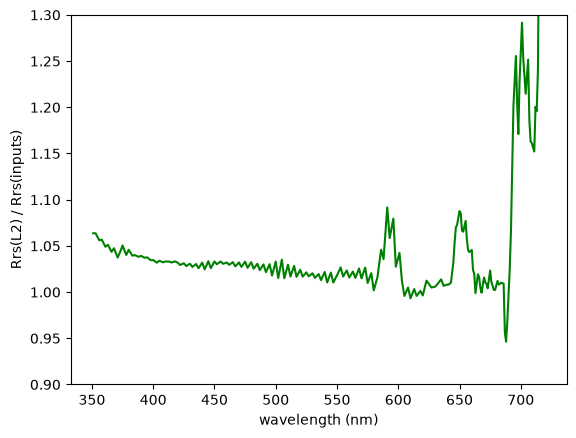

In [70]:
plt.plot(lwl[lidx], rat, color='green', linewidth=1.5)
plt.xlabel("wavelength (nm)")
plt.ylabel("Rrs(L2) / Rrs(inputs)")
plt.ylim(0.9,1.3)